# 01 - Data Selection & the Family-Office Portfolio

**Tail Risk Adequacy** · High_Magus_of_Risk

---

## Objective

Acquire the daily return series for the **diversified family-office (FO) portfolio** and
construct it with realistic monthly rebalancing. The FO is the single portfolio analysed
throughout the project (the old 60/40 and 30/50/20 books are retired).

| Sleeve | Proxy | Weight |
|---|---|---|
| US equity | S&P 500 Total Return (^SP500TR) | 40% |
| US bonds | Vanguard Total Bond (VBMFX) | 25% |
| Real estate | Vanguard REIT (VGSIX) / VNQ | 15% |
| Real assets | Gold (GC=F / XAUUSD) | 10% |
| Cash | 3-month T-bill (DTB3) | 10% |


## 1  Setup

In [1]:
import os, io, json, warnings
warnings.filterwarnings('ignore')
import sys; sys.path.insert(0, 'src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import portfolio as pf                      # tested FO construction (monthly rebalance + costs)
try:
    import yfinance as yf
except Exception as e:
    yf = None; print('yfinance unavailable:', e)
plt.rcParams.update({'figure.figsize': (13, 4), 'axes.grid': True, 'grid.alpha': 0.3})

START, END = '1990-01-01', '2026-04-01'
FO_WEIGHTS = {'SP500_ret': 0.40, 'VBMFX_ret': 0.25, 'REIT_ret': 0.15, 'GLD_ret': 0.10, 'Cash_ret': 0.10}
COST = 0.0010
os.makedirs('data', exist_ok=True)
print('Setup OK | FO weights:', FO_WEIGHTS)

Setup OK | FO weights: {'SP500_ret': 0.4, 'VBMFX_ret': 0.25, 'REIT_ret': 0.15, 'GLD_ret': 0.1, 'Cash_ret': 0.1}


## 2  Acquire the asset data (cache-first)

If the per-sleeve series have already been pulled (`data/returns.csv` for equity/bond/cash and
`data/fo_assets.csv` for gold/REIT, produced by `fetch_fo_assets.py`), we load them and run offline.
Otherwise we download from yfinance / Stooq / FRED. Equity, bond and cash use the same robust
fallbacks as the original pipeline; gold and REIT mirror `fetch_fo_assets.py`.

In [2]:
HDRS = {'User-Agent': 'Mozilla/5.0 (research script)'}

def _close(df):
    if isinstance(df.columns, pd.MultiIndex): df.columns = df.columns.get_level_values(0)
    if 'Close' not in df.columns and 'Adj Close' in df.columns: df = df.rename(columns={'Adj Close': 'Close'})
    if getattr(df.index, 'tz', None) is not None: df.index = df.index.tz_localize(None)
    return df

def _stooq(sym):
    r = requests.get(f'https://stooq.com/q/d/l/?s={sym}&i=d', headers=HDRS, timeout=30); r.raise_for_status()
    if not r.text.lstrip().lower().startswith('date'): raise ValueError(f'Stooq non-CSV (rate-limited?): {r.text[:80]!r}')
    d = pd.read_csv(io.StringIO(r.text)); d['Date'] = pd.to_datetime(d['Date']); return d.set_index('Date').sort_index()

def _localcsv(path):
    d = pd.read_csv(path); low = {c.lower(): c for c in d.columns}
    datecol = low.get('date', d.columns[0]); d = d.rename(columns={datecol: 'Date', low['close']: 'Close'})  # unnamed 1st col = Date
    d['Date'] = pd.to_datetime(d['Date']); d['Close'] = pd.to_numeric(d['Close'], errors='coerce')
    return d.dropna(subset=['Close']).set_index('Date').sort_index()

def _fred_csv(series):
    r = requests.get(f'https://fred.stlouisfed.org/graph/fredgraph.csv?id={series}', timeout=30); r.raise_for_status()
    d = pd.read_csv(io.StringIO(r.text), index_col=0, parse_dates=True); d.columns = [series]
    d[series] = pd.to_numeric(d[series], errors='coerce'); return d.dropna()

def _kenfrench():
    import zipfile
    url = 'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_daily_CSV.zip'
    r = requests.get(url, headers=HDRS, timeout=60); r.raise_for_status()
    z = zipfile.ZipFile(io.BytesIO(r.content)); lines = z.read(z.namelist()[0]).decode('latin-1').splitlines()
    hdr = next(i for i, l in enumerate(lines) if 'RlEst' in l)
    ci = [c.strip() for c in lines[hdr].split(',')].index('RlEst')
    dates, vals = [], []
    for l in lines[hdr+1:]:
        p = l.split(','); d = p[0].strip()
        if not (len(d) == 8 and d.isdigit()): break
        dates.append(pd.to_datetime(d, format='%Y%m%d')); vals.append(float(p[ci]))
    ret = pd.Series(vals, index=dates) / 100.0; ret = ret[ret > -0.99]
    return (1.0 + ret).cumprod().to_frame('Close')   # synthetic level; pct_change recovers TR

def _longest(label, sources):
    best = None
    for nm, fn in sources:
        try:
            s = fn()['Close'].dropna(); assert len(s)
            print(f'  [{label}] {nm}: {len(s)} rows {s.index[0].date()}->{s.index[-1].date()}')
            if best is None or s.index[0] < best.index[0]: best = s
        except Exception as e: print(f'  [{label}] {nm} failed: {e}')
    if best is None: raise RuntimeError(f'all sources failed for {label}')
    return best.to_frame('Close')

if os.path.exists('data/returns.csv') and os.path.exists('data/fo_assets.csv'):
    print('Loading cached per-sleeve series (offline).')
    rr = pd.read_csv('data/returns.csv', index_col=0, parse_dates=True)
    simple = rr[['SP500_ret', 'VBMFX_ret']].copy()
    log_returns = rr[['SP500_log', 'VBMFX_log']].copy()
    cash_daily = rr['Cash_ret'].copy()
    fo = pd.read_csv('data/fo_assets.csv', index_col=0, parse_dates=True)
    simple['GLD_ret'] = fo['GLD_ret']; simple['REIT_ret'] = fo['REIT_ret']
else:
    print('Downloading from yfinance / Stooq / FRED ...')
    eq = _longest('EQUITY', [('yfinance ^SP500TR', lambda: _close(yf.Ticker('^SP500TR').history(period='max', auto_adjust=True, actions=False)))])
    bd = _longest('BOND',   [('yfinance VBMFX', lambda: _close(yf.Ticker('VBMFX').history(period='max', auto_adjust=True, actions=False)))])
    gd = _longest('GOLD',   [('local data/raw/gold.csv', lambda: _localcsv('data/raw/gold.csv')), ('Stooq XAUUSD', lambda: _stooq('xauusd'))])  # FRED dropped LBMA gold; drop a daily CSV in data/raw/gold.csv for 1990 history
    rt = _longest('REIT',   [('yfinance VGSIX', lambda: _close(yf.Ticker('VGSIX').history(period='max', auto_adjust=True, actions=False))), ('yfinance VNQ', lambda: _close(yf.Ticker('VNQ').history(period='max', auto_adjust=True, actions=False)))])  # REIT = Vanguard VGSIX (1996+)
    prices = pd.DataFrame({'SP500': eq['Close'], 'VBMFX': bd['Close']}).loc[START:END]
    log_returns = np.log(prices / prices.shift(1)).dropna(); log_returns.columns = ['SP500_log', 'VBMFX_log']
    simple = prices.pct_change().dropna(); simple.columns = ['SP500_ret', 'VBMFX_ret']
    simple['GLD_ret'] = gd['Close'].pct_change(); simple['REIT_ret'] = rt['Close'].pct_change()
    try: tb = _fred_csv('DTB3'); cash_daily = (tb['DTB3'] / 100 / 252)
    except Exception as e: print('cash via FRED failed, using 2%:', e); cash_daily = None
    cash_daily = (pd.Series(0.02/252, index=simple.index) if cash_daily is None else cash_daily).reindex(simple.index, method='ffill').fillna(0)
    prices.to_csv('data/prices.csv')

simple = simple.dropna()
print('Asset return matrix:', simple.shape, '|', simple.index[0].date(), '->', simple.index[-1].date())

Loading cached per-sleeve series (offline).
Asset return matrix: (7485, 4) | 1996-05-14 -> 2026-04-01


## 3  Build the FO portfolio (monthly-rebalanced, costed)

In [3]:
asset_returns = simple.copy()
asset_returns['Cash_ret'] = cash_daily.reindex(simple.index).ffill().fillna(0)
asset_returns = asset_returns[['SP500_ret', 'VBMFX_ret', 'REIT_ret', 'GLD_ret', 'Cash_ret']].dropna()

Port_FO = pf.build_rebalanced_portfolio(asset_returns[list(FO_WEIGHTS)], FO_WEIGHTS, cadence='M', cost=COST)
asset_returns['Port_FO'] = Port_FO

print('FO sample:', asset_returns.index[0].date(), '->', asset_returns.index[-1].date(), '| n =', len(asset_returns))
print('Port_FO  ann return %.2f%% | ann vol %.2f%%' % (100*Port_FO.mean()*252, 100*Port_FO.std()*np.sqrt(252)))
s = asset_returns.describe().T
s['ann_mean'] = s['mean']*252; s['ann_std'] = s['std']*np.sqrt(252)
s[['mean', 'std', 'min', 'max', 'ann_mean', 'ann_std']].round(8)

FO sample: 1996-05-14 -> 2026-04-01 | n = 7485
Port_FO  ann return 7.99% | ann vol 10.93%


,mean,std,min,max,ann_mean,ann_std
SP500_ret,0.000452,0.012072,-0.119799,0.115811,0.113951,0.191632
VBMFX_ret,0.000166,0.002813,-0.016769,0.019502,0.041946,0.044647
REIT_ret,0.000363,0.017358,-0.176400,0.163600,0.091377,0.275556
GLD_ret,0.000390,0.010617,-0.098703,0.105724,0.098257,0.168537
Cash_ret,0.000090,0.000082,-0.000002,0.000248,0.022627,0.001294
Port_FO,0.000317,0.006885,-0.069627,0.052714,0.079895,0.109300


---
## 4  Correlation across the FO sleeves

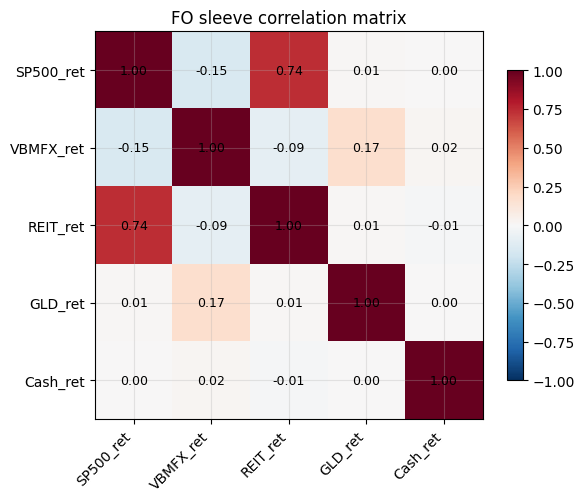

,SP500_ret,VBMFX_ret,REIT_ret,GLD_ret,Cash_ret
SP500_ret,1.000,-0.152,0.735,0.013,0.001
VBMFX_ret,-0.152,1.000,-0.089,0.168,0.023
REIT_ret,0.735,-0.089,1.000,0.010,-0.012
GLD_ret,0.013,0.168,0.010,1.000,0.003
Cash_ret,0.001,0.023,-0.012,0.003,1.000


In [4]:
corr = asset_returns[['SP500_ret', 'VBMFX_ret', 'REIT_ret', 'GLD_ret', 'Cash_ret']].corr()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr.values, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.values[i, j]:.2f}', ha='center', va='center', fontsize=9)
fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title('FO sleeve correlation matrix')
plt.tight_layout(); plt.show()
corr.round(3)

---
## 5  Visual inspection

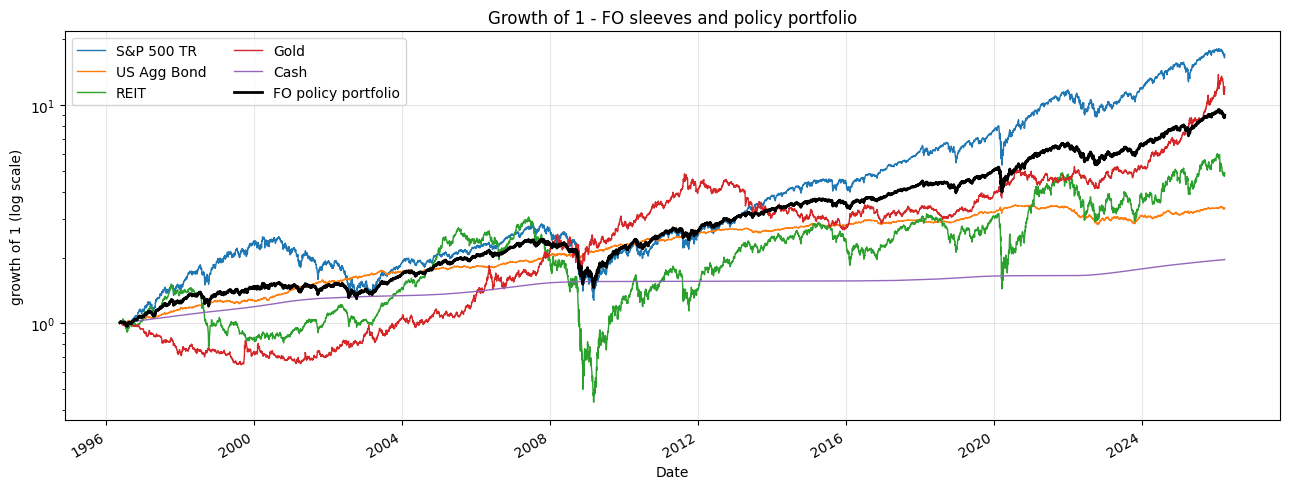

In [5]:
fig, ax = plt.subplots(figsize=(13, 5))
labels = {'SP500_ret': 'S&P 500 TR', 'VBMFX_ret': 'US Agg Bond', 'REIT_ret': 'REIT',
          'GLD_ret': 'Gold', 'Cash_ret': 'Cash'}
for col, lab in labels.items():
    (1 + asset_returns[col]).cumprod().plot(ax=ax, lw=1.0, label=lab)
(1 + Port_FO).cumprod().plot(ax=ax, color='k', lw=2.0, label='FO policy portfolio')
ax.set_yscale('log'); ax.set_ylabel('growth of 1 (log scale)')
ax.set_title('Growth of 1 - FO sleeves and policy portfolio')
ax.legend(ncol=2)
plt.tight_layout(); plt.show()

---
## 6  Save returns, FO-sleeve cache and metadata

In [6]:
all_returns = pd.concat([
    asset_returns[['SP500_ret', 'VBMFX_ret', 'REIT_ret', 'GLD_ret', 'Cash_ret']],
    log_returns.reindex(asset_returns.index), asset_returns[['Port_FO']]], axis=1)
all_returns.to_csv('data/returns.csv')
asset_returns[['GLD_ret', 'REIT_ret']].dropna().to_csv('data/fo_assets.csv')   # FO sleeve cache for NB11 et al.
with open('data/metadata.json', 'w') as f:
    json.dump({'START': START, 'END': END, 'portfolio': 'Port_FO', 'weights': FO_WEIGHTS,
               'sample_start': str(asset_returns.index[0].date()), 'sample_end': str(asset_returns.index[-1].date())}, f, indent=2)
print('Saved data/returns.csv', all_returns.shape, '| fo_assets.csv', asset_returns[['GLD_ret', 'REIT_ret']].dropna().shape,
      '|', asset_returns.index[0].date(), '->', asset_returns.index[-1].date())

Saved data/returns.csv (7485, 8) | fo_assets.csv (7485, 2) | 1996-05-14 -> 2026-04-01
